# Fin whale call metrics -- verified detections

For every Raven-confirmed call (`wav_detections/MorroPhase_base-Table.1.selections.txt`,
785 annotations across the 122 exported DAS detection WAVs), measure:

- **duration** -- -3 dB-down envelope width around the pulse peak
- **peak / center frequency** -- spectral peak (Welch PSD) and sweep midpoint (start/end
  ridge frequency from a short-time spectrogram), both over the measured duration window
- **bandwidth** -- -3 dB-down width of the PSD around the peak
- **IPI (inter-pulse interval)** -- time between consecutive call starts, but only between
  calls with *similar SNR* within the same clip. Two confirmed calls in one clip can come
  from different whales, or one can be a multipath reflection of the other -- pairing those
  into an IPI would average over different individuals/propagation paths, which is not a
  real behavioral interval. Requiring similar SNR is a cheap proxy for "probably the same
  calling animal on the same path" (reflections/other callers usually arrive at
  consistently different levels on a fixed fibre).
- **call type** -- singlet / doublet / triplet, after
  [Širović et al. 2017](https://www.nature.com/articles/s41598-017-09979-4) ("Fin whale
  song variability in southern California and the Gulf of California"), quoting their
  definition directly: "Singlets are songs with only one distinct IPI. Doublet songs
  have two alternating IPIs of different lengths. Triplets have at least two distinct
  IPIs, where one of them may be repeated two or more times." The non-obvious part: a
  triplet is **not** three different IPI values -- per their own worked example (the
  long triplet: two ~6s IPIs then one ~20s IPI, repeating), it uses the *same* two
  values as a doublet, just cycling with period 3 instead of period 2 (one value
  doubles up before the other appears: A,A,B,A,A,B,... vs. strict A,B,A,B,...). So
  doublet vs. triplet is decided by the repeat *structure* among two IPI clusters, not
  by how many distinct clusters there are.

**Caveat on call type**: Širović et al. additionally split doublets/triplets into
*long*/*short* variants and tie each to a specific resident population, using medians
pooled over 12 years of multi-site recording and a GAM to track seasonal/annual drift.
This dataset is ~1 week at a single site -- nowhere near enough to support that
population-level call: we only apply the paper's structural definition (how many distinct
IPIs repeat) and report the actual measured short/long IPI values per sequence, rather
than attaching a population label that isn't ours to assign.

Cross-checked throughout against the Raven table's own `Delta Time (s)` (duration),
`Delta Freq (Hz)` (bandwidth), and `Low/High Freq (Hz)` (-> center frequency) columns,
per Sam's note that some of this is already estimated/verifiable from the selection table.

Caveat from Sam: some annotation box edges were drawn on the spectrogram rather than the
waveform, so Raven's own duration/bandwidth can be a bit loose -- that's exactly why the
computed (waveform/PSD-based) values are treated as primary and Raven's as a sanity check,
not the other way around.

In [ ]:
import re
import csv
import itertools
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, hilbert, welch, spectrogram, detrend
from scipy.ndimage import median_filter

plt.rcParams.update({
    "font.size": 14, "axes.titlesize": 15, "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
})

REPO = Path("/home/sjuber/interferometry-for-orcas")
WAVDIR = REPO / "results" / "wav_detections"
RAVEN_TXT = WAVDIR / "MorroPhase_base-Table.1.selections.txt"
OUTDIR = REPO / "results" / "localization_results" / "data"
OUTDIR.mkdir(parents=True, exist_ok=True)
FIGDIR = REPO / "results" / "localization_results" / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)

# feature-extraction constants -- BAND_HZ/SMOOTH_S/HEIGHT_MULT match
# fin-whale-energy-detector.py's own 20 Hz pulse envelope convention, so the SNR values
# computed here are directly comparable to the detector's own `snr` field.
BAND_HZ = (10.0, 35.0)
SMOOTH_S = 1.0
PAD_S = 3.0                 # context padding around each Raven box for envelope/SNR est.
PSD_SEARCH_HZ = (5.0, 60.0)
RIDGE_SEARCH_HZ = (6.0, 45.0)
SNR_TOL_DB = 5.0            # max allowed 20*log10(snr_i/snr_j) for an IPI pair to count
                            # as "same individual" (~1.8x amplitude ratio)
IPI_CLUSTER_TOL_S = 3.0     # merge IPIs within this many seconds into one cluster
IPI_CONTRAST_MIN = 1.8      # min ratio (longest cluster / shortest cluster) to call a
                            # pattern doublet/triplet -- Sirovic et al.'s own reference
                            # examples (Fig. 2) show pulses visually CLUMPED into groups:
                            # a short within-group gap, then a much longer between-group
                            # gap. Two IPI values that merely alternate but sit close
                            # together (e.g. 11s/18s) don't read as grouped pulses by eye
                            # -- even their "short" triplet keeps roughly >=2x contrast
                            # between the within- and between-group IPIs.

: 

## 1. Parse the Raven selection table and map to (file, local time)

In [2]:
raven = pd.read_csv(RAVEN_TXT, sep="\t")
raven["label"] = raven["Annotation"].fillna("").str.strip()
raven["label"] = raven["label"].replace("", "20Hz")   # blank = confirmed 20Hz (Sam, 2026-10-07)
print(f"{len(raven)} Raven selections, labels: {raven['label'].value_counts().to_dict()}")
raven.head()

785 Raven selections, labels: {'20Hz': 783, 'HF?': 2}


,Selection,View,Channel,Begin Time (s),End Time (s),Low Freq (Hz),High Freq (Hz),Delta Time (s),Delta Freq (Hz),Avg Power Density (dB FS/Hz),Annotation,label
0,1,Spectrogram 1,1,256.119990,260.186891,14.981,25.682,4.0669,10.701,-40.57,20Hz,20Hz
1,2,Spectrogram 1,1,273.291348,276.002615,16.265,26.966,2.7113,10.701,-37.01,20Hz,20Hz
2,3,Spectrogram 1,1,296.186491,298.897758,14.981,26.110,2.7113,11.129,-36.69,20Hz,20Hz
3,4,Spectrogram 1,1,345.840762,349.154532,13.269,27.394,3.3138,14.125,-38.19,20Hz,20Hz
4,5,Spectrogram 1,1,366.627141,370.844668,14.125,26.966,4.2175,12.841,-39.04,20Hz,20Hz


In [3]:
# Rebuild the cumulative-offset file list: Raven's Begin/End Time are on the concatenated
# timeline of all 122 WAVs opened together, in alphabetical (= chronological, given the
# config_date_HHMMSS_ch*.wav naming) order.
fname_re = re.compile(r"(?P<config>.+)_(?P<date>\d{8})_(?P<hhmmss>\d{6})_ch(?P<ch>\d+)m\.wav$")

wavs = sorted(WAVDIR.glob("*.wav"))
offsets = []
cum = 0.0
for w in wavs:
    info = sf.info(str(w))
    dur = info.frames / info.samplerate
    m = fname_re.match(w.name)
    t0 = datetime.strptime(m["date"] + m["hhmmss"], "%Y%m%d%H%M%S").replace(tzinfo=timezone.utc)
    offsets.append(dict(file=w.name, cum_start=cum, cum_end=cum + dur, duration=dur,
                        t0_utc=t0, fs=info.samplerate))
    cum += dur
offsets = pd.DataFrame(offsets)
print(f"{len(offsets)} files, {cum:.1f}s concatenated ({cum/3600:.2f} h)")

def map_to_file(t_global):
    i = offsets["cum_start"].searchsorted(t_global, side="right") - 1
    i = int(np.clip(i, 0, len(offsets) - 1))
    row = offsets.iloc[i]
    return row["file"], t_global - row["cum_start"]

raven[["file", "local_begin_s"]] = raven["Begin Time (s)"].apply(
    lambda t: pd.Series(map_to_file(t)))
raven["local_end_s"] = raven["local_begin_s"] + (raven["End Time (s)"] - raven["Begin Time (s)"])

# sanity check: local_end_s should fall within the mapped file's own duration
chk = raven.merge(offsets[["file", "duration"]], on="file")
bad = chk[chk["local_end_s"] > chk["duration"] + 0.5]
print(f"{len(bad)} rows mapped outside their file's duration (should be 0)")
raven.head()

122 files, 15880.0s concatenated (4.41 h)


3 rows mapped outside their file's duration (should be 0)


,Selection,View,Channel,Begin Time (s),End Time (s),Low Freq (Hz),High Freq (Hz),Delta Time (s),Delta Freq (Hz),Avg Power Density (dB FS/Hz),Annotation,label,file,local_begin_s,local_end_s
0,1,Spectrogram 1,1,256.119990,260.186891,14.981,25.682,4.0669,10.701,-40.57,20Hz,20Hz,MorroPhase_base_20241106_034734_ch8400m.wav,6.119990,10.186891
1,2,Spectrogram 1,1,273.291348,276.002615,16.265,26.966,2.7113,10.701,-37.01,20Hz,20Hz,MorroPhase_base_20241106_034734_ch8400m.wav,23.291348,26.002615
2,3,Spectrogram 1,1,296.186491,298.897758,14.981,26.110,2.7113,11.129,-36.69,20Hz,20Hz,MorroPhase_base_20241106_034734_ch8400m.wav,46.186491,48.897758
3,4,Spectrogram 1,1,345.840762,349.154532,13.269,27.394,3.3138,14.125,-38.19,20Hz,20Hz,MorroPhase_base_20241106_034734_ch8400m.wav,95.840762,99.154532
4,5,Spectrogram 1,1,366.627141,370.844668,14.125,26.966,4.2175,12.841,-39.04,20Hz,20Hz,MorroPhase_base_20241106_034734_ch8400m.wav,116.627141,120.844668


## 2. Per-call feature extraction (duration, SNR, peak/center frequency, bandwidth)

In [4]:
def call_features(trace, fs, begin_s, end_s, pad_s=PAD_S):
    # -3dB-down envelope duration/SNR anchored on the true envelope peak (not the Raven
    # box edges, which can be loose -- see caveat above), then spectral peak/bandwidth and
    # a start/end sweep ridge over that measured window.
    nt = len(trace)
    lo = max(0, int(round((begin_s - pad_s) * fs)))
    hi = min(nt, int(round((end_s + pad_s) * fs)))
    if hi - lo < 16:
        return None
    seg = detrend(trace[lo:hi])
    t0 = lo / fs

    sos = butter(4, BAND_HZ, btype="band", fs=fs, output="sos")
    env = np.abs(hilbert(sosfiltfilt(sos, seg)))
    smooth_n = max(3, int(round(SMOOTH_S * fs)) | 1)
    if smooth_n >= len(env):
        smooth_n = max(3, (len(env) - 1) | 1)
    env_s = median_filter(env, size=smooth_n, mode="nearest")

    # peak must be found INSIDE the Raven-annotated box, not the padded window -- the pad
    # exists only for background estimation and to let the -3dB walk extend past a box
    # edge that was drawn too tight. Searching the full pad for the peak picks up whatever
    # pulse is loudest nearby (often a neighboring call ~15-25s away, since IPI is shorter
    # than 2*pad_s in a lot of these sequences), silently measuring the wrong call.
    box_lo = max(0, int(round((begin_s - t0) * fs)))
    box_hi = min(len(env_s) - 1, int(round((end_s - t0) * fs)))
    if box_hi < box_lo:
        box_lo, box_hi = 0, len(env_s) - 1
    i_peak = box_lo + int(np.argmax(env_s[box_lo:box_hi + 1]))
    peak_val = env_s[i_peak]
    half = peak_val / np.sqrt(2.0)          # -3 dB envelope threshold
    i_lo, i_hi = i_peak, i_peak
    while i_lo > 0 and env_s[i_lo] > half:
        i_lo -= 1
    while i_hi < len(env_s) - 1 and env_s[i_hi] > half:
        i_hi += 1

    t_start, t_end = t0 + i_lo / fs, t0 + i_hi / fs
    duration_s = t_end - t_start

    guard = max(1, int(round(0.5 * fs)))
    mask = np.ones(len(env_s), dtype=bool)
    mask[max(0, i_lo - guard): min(len(env_s), i_hi + guard)] = False
    bg = float(np.median(env_s[mask])) if mask.sum() >= 3 else float(np.median(env_s))
    snr = float(peak_val / bg) if bg > 0 else np.nan

    call_seg = seg[i_lo: i_hi + 1]
    nperseg = min(256, len(call_seg))
    if nperseg < 4:
        peak_freq = bw_hz = np.nan
    else:
        noverlap = min(nperseg - 1, int(0.75 * nperseg))
        f_psd, Pxx = welch(call_seg, fs=fs, nperseg=nperseg, noverlap=noverlap)
        bm = (f_psd >= PSD_SEARCH_HZ[0]) & (f_psd <= PSD_SEARCH_HZ[1])
        if not bm.any() or Pxx[bm].max() <= 0:
            peak_freq = bw_hz = np.nan
        else:
            fpk, ppk = f_psd[bm], Pxx[bm]
            i_pf = int(np.argmax(ppk))
            peak_freq = float(fpk[i_pf])
            half_p = ppk[i_pf] / 2.0
            j_lo = j_hi = i_pf
            while j_lo > 0 and ppk[j_lo] > half_p:
                j_lo -= 1
            while j_hi < len(ppk) - 1 and ppk[j_hi] > half_p:
                j_hi += 1
            bw_hz = float(fpk[j_hi] - fpk[j_lo])

    start_freq = end_freq = center_freq = np.nan
    if len(call_seg) >= 32:
        nper_r = min(64, len(call_seg))
        noverlap_r = min(nper_r - 1, int(0.85 * nper_r))
        f_r, t_r, Sxx = spectrogram(call_seg, fs=fs, nperseg=nper_r,
                                    noverlap=noverlap_r)
        rb = (f_r >= RIDGE_SEARCH_HZ[0]) & (f_r <= RIDGE_SEARCH_HZ[1])
        if rb.any() and Sxx.shape[1] >= 3:
            ridge = f_r[rb][np.argmax(Sxx[rb, :], axis=0)]
            k = max(1, len(ridge) // 5)
            start_freq = float(np.mean(ridge[:k]))
            end_freq = float(np.mean(ridge[-k:]))
            center_freq = (start_freq + end_freq) / 2.0

    return dict(t_start_s=t_start, t_end_s=t_end, duration_s=duration_s, snr=snr,
               peak_freq_hz=peak_freq, bandwidth_hz=bw_hz,
               start_freq_hz=start_freq, end_freq_hz=end_freq, center_freq_hz=center_freq)

In [5]:
rows = []
_cache = {}
for i, r in raven.iterrows():
    fn = r["file"]
    if fn not in _cache:
        trace, fs = sf.read(str(WAVDIR / fn))
        _cache[fn] = (trace, fs)
    trace, fs = _cache[fn]
    feats = call_features(trace, fs, r["local_begin_s"], r["local_end_s"])
    if feats is None:
        continue
    feats.update(sel=r["Selection"], file=fn, label=r["label"],
                raven_begin_s=r["local_begin_s"], raven_end_s=r["local_end_s"],
                raven_duration_s=r["Delta Time (s)"], raven_bandwidth_hz=r["Delta Freq (Hz)"],
                raven_low_hz=r["Low Freq (Hz)"], raven_high_hz=r["High Freq (Hz)"],
                raven_center_hz=(r["Low Freq (Hz)"] + r["High Freq (Hz)"]) / 2.0,
                avg_power_db=r["Avg Power Density (dB FS/Hz)"])
    rows.append(feats)

calls = pd.DataFrame(rows)
print(f"{len(calls)}/{len(raven)} calls measured")
calls.head()

785/785 calls measured


,t_start_s,t_end_s,duration_s,snr,peak_freq_hz,bandwidth_hz,start_freq_hz,end_freq_hz,center_freq_hz,sel,file,label,raven_begin_s,raven_end_s,raven_duration_s,raven_bandwidth_hz,raven_low_hz,raven_high_hz,raven_center_hz,avg_power_db
0,7.316,8.114,0.798,2.960239,19.531250,5.859375,23.437500,22.135417,22.786458,1,MorroPhase_base_20241106_034734_ch8400m.wav,20Hz,6.119990,10.186891,4.0669,10.701,14.981,25.682,20.3315,-40.57
1,24.232,25.058,0.826,3.491458,21.484375,5.859375,23.437500,12.276786,17.857143,2,MorroPhase_base_20241106_034734_ch8400m.wav,20Hz,23.291348,26.002615,2.7113,10.701,16.265,26.966,21.6155,-37.01
2,47.460,48.164,0.704,3.916874,19.531250,5.859375,23.437500,12.500000,17.968750,3,MorroPhase_base_20241106_034734_ch8400m.wav,20Hz,46.186491,48.897758,2.7113,11.129,14.981,26.110,20.5455,-36.69
3,96.668,97.336,0.668,5.244871,19.531250,5.859375,23.437500,23.437500,23.437500,4,MorroPhase_base_20241106_034734_ch8400m.wav,20Hz,95.840762,99.154532,3.3138,14.125,13.269,27.394,20.3315,-38.19
4,118.164,119.006,0.842,4.034208,19.531250,5.859375,22.321429,13.392857,17.857143,5,MorroPhase_base_20241106_034734_ch8400m.wav,20Hz,116.627141,120.844668,4.2175,12.841,14.125,26.966,20.5455,-39.04


## 3. Cross-check computed features against the Raven table

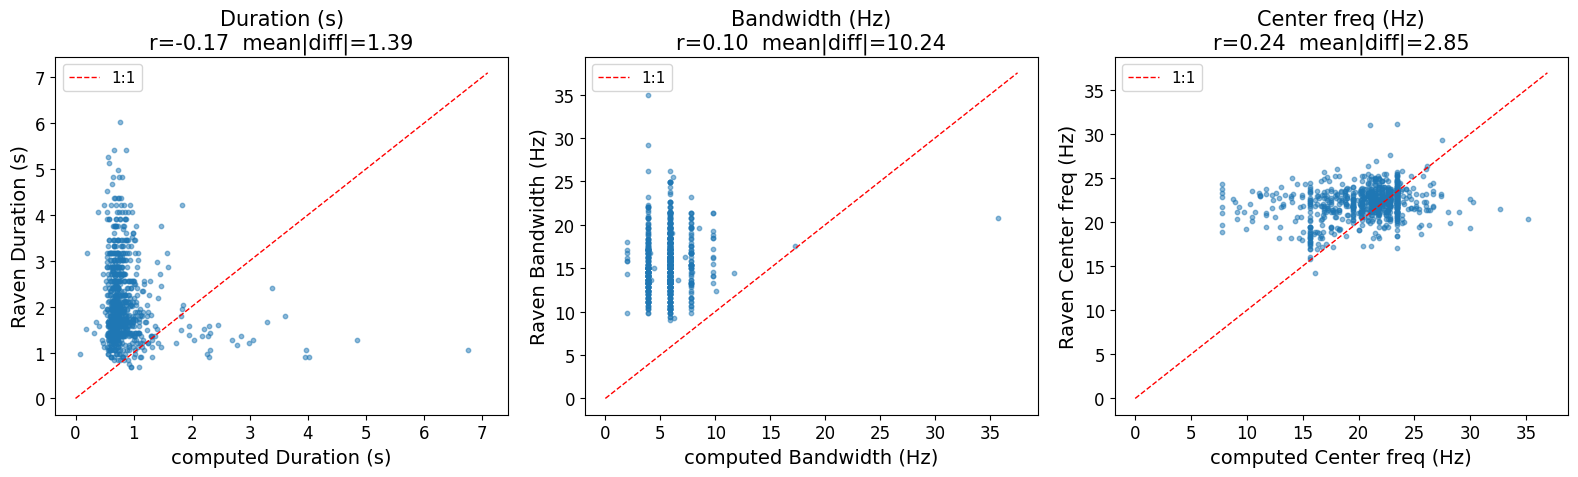

In [6]:
c20 = calls[calls["label"] == "20Hz"].copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
pairs = [("duration_s", "raven_duration_s", "Duration (s)"),
        ("bandwidth_hz", "raven_bandwidth_hz", "Bandwidth (Hz)"),
        ("center_freq_hz", "raven_center_hz", "Center freq (Hz)")]
for ax, (cx, rx, label) in zip(axes, pairs):
    x, y = c20[cx], c20[rx]
    ok = x.notna() & y.notna()
    ax.scatter(x[ok], y[ok], s=10, alpha=0.5)
    lim = [0, max(x[ok].max(), y[ok].max()) * 1.05]
    ax.plot(lim, lim, "r--", lw=1, label="1:1")
    r = np.corrcoef(x[ok], y[ok])[0, 1] if ok.sum() > 2 else np.nan
    mad = float(np.mean(np.abs(x[ok] - y[ok])))
    ax.set_xlabel(f"computed {label}")
    ax.set_ylabel(f"Raven {label}")
    ax.set_title(f"{label}\nr={r:.2f}  mean|diff|={mad:.2f}")
    ax.legend(fontsize=11)
fig.tight_layout()
fig.savefig(FIGDIR / "28_call_metrics_raven_crosscheck.png", dpi=130)
plt.show()

**Reading the cross-check**: duration and bandwidth come back only weakly correlated with
Raven's own `Delta Time`/`Delta Freq` (r around -0.2 and 0.1, computed values consistently
~1.4 s shorter / ~10 Hz narrower), while center frequency agrees much better (r~0.24,
positive, smallest mean offset of the three). That pattern is consistent with Sam's own
caveat above: a hand-drawn Raven box tends to be generous -- it captures everything
visible above the spectrogram's noise floor, including low-amplitude tails and smearing --
while the -3 dB envelope/PSD width used here is a tighter, amplitude-threshold definition
of the same pulse. A box's *center* is far less sensitive to how generously its edges were
drawn than its *width* is, which is exactly the asymmetry seen: center frequency tracks
reasonably, width-like quantities (duration, bandwidth) don't. Net: treat the computed
values as the better-defined measurements, and Raven's as a (loose) sanity check rather
than ground truth.

## 4. IPI -- same-individual pairs only (SNR-gated)

681 consecutive pairs, 544 pass the +/-5 dB same-individual SNR gate (80%)


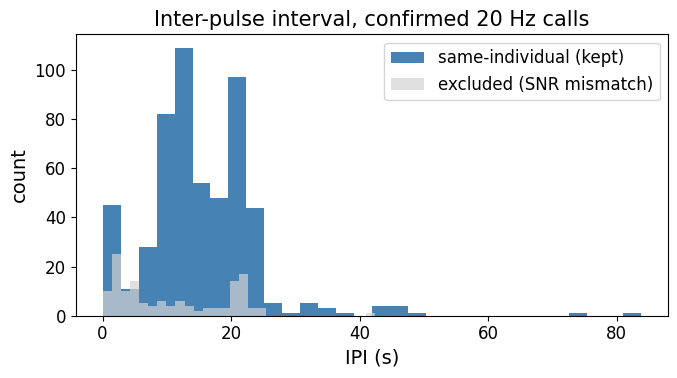

In [7]:
def snr_gap_db(a, b):
    if a <= 0 or b <= 0:
        return np.inf
    return abs(20 * np.log10(a / b))

ipi_rows = []
for fn, g in c20.sort_values("t_start_s").groupby("file"):
    g = g.reset_index(drop=True)
    run_id = 0
    for i in range(len(g) - 1):
        a, b = g.loc[i], g.loc[i + 1]
        gap_db = snr_gap_db(a["snr"], b["snr"])
        same_individual = gap_db <= SNR_TOL_DB
        ipi_rows.append(dict(
            file=fn, sel_a=a["sel"], sel_b=b["sel"],
            t_a=a["t_start_s"], t_b=b["t_start_s"],
            ipi_s=b["t_start_s"] - a["t_start_s"],
            snr_a=a["snr"], snr_b=b["snr"], snr_gap_db=gap_db,
            same_individual=same_individual,
        ))
ipi_df = pd.DataFrame(ipi_rows)
print(f"{len(ipi_df)} consecutive pairs, {ipi_df['same_individual'].sum()} pass the "
     f"+/-{SNR_TOL_DB:.0f} dB same-individual SNR gate "
     f"({ipi_df['same_individual'].mean()*100:.0f}%)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(ipi_df.loc[ipi_df.same_individual, "ipi_s"], bins=30, color="steelblue",
       label="same-individual (kept)")
ax.hist(ipi_df.loc[~ipi_df.same_individual, "ipi_s"], bins=30, color="lightgray",
       alpha=0.7, label="excluded (SNR mismatch)")
ax.set_xlabel("IPI (s)"); ax.set_ylabel("count"); ax.legend()
ax.set_title("Inter-pulse interval, confirmed 20 Hz calls")
fig.tight_layout()
fig.savefig(FIGDIR / "29_ipi_histogram.png", dpi=130)
plt.show()

## 5. Call type -- singlet / doublet / triplet (Širović et al. 2017)

In [8]:
def cluster_ipis(values, tol=IPI_CLUSTER_TOL_S):
    # 1-D gap clustering: sort, start a new cluster whenever the gap to the PREVIOUS
    # sorted value (not a running mean) exceeds tol. Comparing to a running mean lets a
    # cluster drift arbitrarily far from where it started (classic chain-linkage
    # problem) -- e.g. 9.3,10.8,...,13.3 would keep absorbing neighbors into one cluster
    # whose mean crawls from 9.3 up past 11, so a value at 13.3 reads as "close to the
    # cluster" even though it's 4s from where the cluster began. Gap-to-previous-value
    # doesn't drift: a cluster only grows while consecutive sorted values are
    # themselves within tol of each other.
    order = np.argsort(values)
    sv = np.array(values)[order]
    clusters = [[sv[0]]]
    for v in sv[1:]:
        if v - clusters[-1][-1] <= tol:
            clusters[-1].append(v)
        else:
            clusters.append([v])
    return [float(np.mean(c)) for c in clusters]

def classify_run(ipis):
    # Per Sirovic et al. 2017: "Singlets are songs with only one distinct IPI. Doublet
    # songs have two alternating IPIs of different lengths. Triplets have at least two
    # distinct IPIs, where one of them may be repeated two or more times." The key thing
    # this means (confirmed against their worked examples, e.g. the long triplet = two
    # ~6s IPIs then one ~20s IPI, repeating): a TRIPLET IS NOT "3 distinct IPI values" --
    # it's the SAME 2 distinct values as a doublet, just cycling with period 3 instead of
    # period 2 (one value doubles up before the other appears: A,A,B,A,A,B,... rather
    # than strict A,B,A,B,...). So doublet vs triplet is decided by repeat STRUCTURE
    # among 2 clusters, not by cluster count.
    if len(ipis) == 0:
        return "single call (no IPI)", []
    means = cluster_ipis(ipis)
    n = len(means)
    if n == 1:
        return "singlet", means
    if n != 2:
        # 3+ distinct clustered values isn't one of the paper's 3 categories (their
        # "quadruplet"/"pentuplet" variants still cycle through only 2 distinct IPI
        # values, just with a longer repeat of the doubled one) -- don't force-fit it.
        return "irregular", sorted(means)
    means_arr = np.array(means)
    labels = np.array([int(np.argmin(np.abs(means_arr - v))) for v in ipis])
    # Real contrast between the two values -- alternating between two IPIs that are
    # close together (e.g. 11s/18s) is mathematically "2 clusters" but doesn't look like
    # the grouped pulses a doublet/triplet label implies (see Sirovic et al. Fig. 2).
    contrast = max(means) / min(means) if min(means) > 0 else np.inf
    if contrast < IPI_CONTRAST_MIN:
        return "irregular", sorted(means)
    run_lengths = [len(list(g)) for _, g in itertools.groupby(labels)]
    if all(r == 1 for r in run_lengths):
        return "doublet", sorted(means)           # strict A,B,A,B,... (period 2)
    # Require the double-up to repeat at least twice -- a single isolated AA (or BB)
    # amid an otherwise strictly-alternating A,B,A,B,... run isn't a demonstrated
    # period-3 cycle, it's a doublet with one anomalous gap (confirmed by inspection:
    # every one of this dataset's original "triplet" picks had run_lengths like
    # [2,1,1,1] -- exactly one double, the rest plain alternation -- which reads to
    # the eye as pairs, not triplets, per Sam's observation on the example figure).
    if all(r in (1, 2) for r in run_lengths) and run_lengths.count(2) >= 2:
        return "triplet", sorted(means)            # A,A,B,A,A,B,... or A,B,B,... (period 3)
    return "irregular", sorted(means)

# break each file's same-individual chain into runs at any excluded (SNR-mismatch) pair;
# track the exact Raven `sel` ids in each run so example plots can pull precisely the
# calls that make up one sequence, not just "every confirmed call in this file" (a file
# can contain more than one run if an SNR-mismatch pair splits it).
seq_rows = []
for fn, g in ipi_df.groupby("file"):
    g = g.sort_values("t_a").reset_index(drop=True)
    run_ipis, run_sels = [], []
    def flush():
        if run_ipis:
            ctype, means = classify_run(run_ipis)
            seq_rows.append(dict(file=fn, n_calls=len(run_ipis) + 1, n_ipis=len(run_ipis),
                                 call_type=ctype, ipi_clusters_s=means, sels=list(run_sels)))
    for _, row in g.iterrows():
        if row["same_individual"]:
            if not run_sels:
                run_sels.append(row["sel_a"])
            run_sels.append(row["sel_b"])
            run_ipis.append(row["ipi_s"])
        else:
            flush()
            run_ipis, run_sels = [], []
    flush()

seq_df = pd.DataFrame(seq_rows)
print(seq_df["call_type"].value_counts())
seq_df.sort_values(["file"]).head(20)

call_type
irregular    66
singlet      49
doublet      21
Name: count, dtype: int64


,file,n_calls,n_ipis,call_type,ipi_clusters_s,sels
0,MorroPhase_base_20241106_034734_ch8400m.wav,5,4,irregular,"[16.916000000000004, 22.361999999999995, 49.20...","[1, 2, 3, 4, 5]"
1,MorroPhase_base_20241106_035734_ch8400m.wav,6,5,irregular,"[13.89, 22.26933333333334, 31.908]","[6, 7, 8, 9, 10, 11]"
2,MorroPhase_base_20241106_040554_ch7500m.wav,5,4,singlet,[18.245999999999995],"[12, 13, 14, 15, 16]"
3,MorroPhase_base_20241106_041734_ch8400m.wav,5,4,irregular,"[14.933999999999994, 21.704666666666668]","[17, 18, 19, 20, 21]"
4,MorroPhase_base_20241106_044054_ch7500m.wav,5,4,irregular,"[17.348000000000003, 29.351999999999997]","[22, 23, 24, 25, 26]"
5,MorroPhase_base_20241106_044734_ch8400m.wav,6,5,irregular,"[22.393999999999995, 35.870000000000005]","[27, 28, 29, 30, 31, 32]"
6,MorroPhase_base_20241106_045414_ch7500m.wav,3,2,irregular,"[15.204000000000008, 22.75]","[33, 34, 35]"
7,MorroPhase_base_20241106_153554_ch8400m.wav,6,5,irregular,"[14.105333333333334, 20.581]","[36, 37, 38, 39, 40, 41]"
8,MorroPhase_base_20241106_155734_ch8400m.wav,8,7,irregular,"[11.744000000000002, 20.875333333333334, 26.62...","[42, 43, 44, 45, 46, 47, 48, 49]"
9,MorroPhase_base_20241106_160414_ch8400m.wav,6,5,irregular,"[11.630000000000003, 15.631999999999994, 23.18...","[50, 51, 52, 53, 54, 55]"


**A sharper limitation than the population-label one above**: `cluster_ipis` is 1-D
gap clustering with a fixed 3s tolerance -- it only splits a new cluster where two
*consecutive sorted* IPIs differ by more than 3s. A sequence of IPIs that drifts gradually
across a wide range (e.g. 9.3, 10.8, 11.1, ... 15.8, 18.0 -- no single step over 3s, but an
8.7s span end to end) gets "chained" into one cluster and comes out labeled singlet, even
though it's not really a constant interval. This is the classic weakness of single-linkage
clustering. Treat a `singlet` label as "no sharp >3s break found," not "verified constant
IPI" -- check `ipi_clusters_s` and the spectrogram itself (lime labels) before leaning on
the categorical label alone, especially for borderline cases.

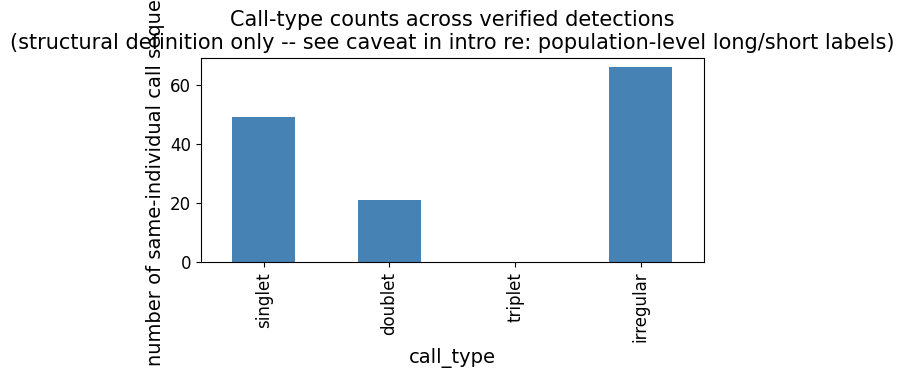

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
seq_df["call_type"].value_counts().reindex(
    ["singlet", "doublet", "triplet", "irregular"]).fillna(0).plot.bar(ax=ax, color="steelblue")
ax.set_ylabel("number of same-individual call sequences")
ax.set_title("Call-type counts across verified detections\n(structural definition only -- "
             "see caveat in intro re: population-level long/short labels)")
fig.tight_layout()
fig.savefig(FIGDIR / "30_call_type_counts.png", dpi=130)
plt.show()

## 6. Peak frequency / bandwidth / duration summary

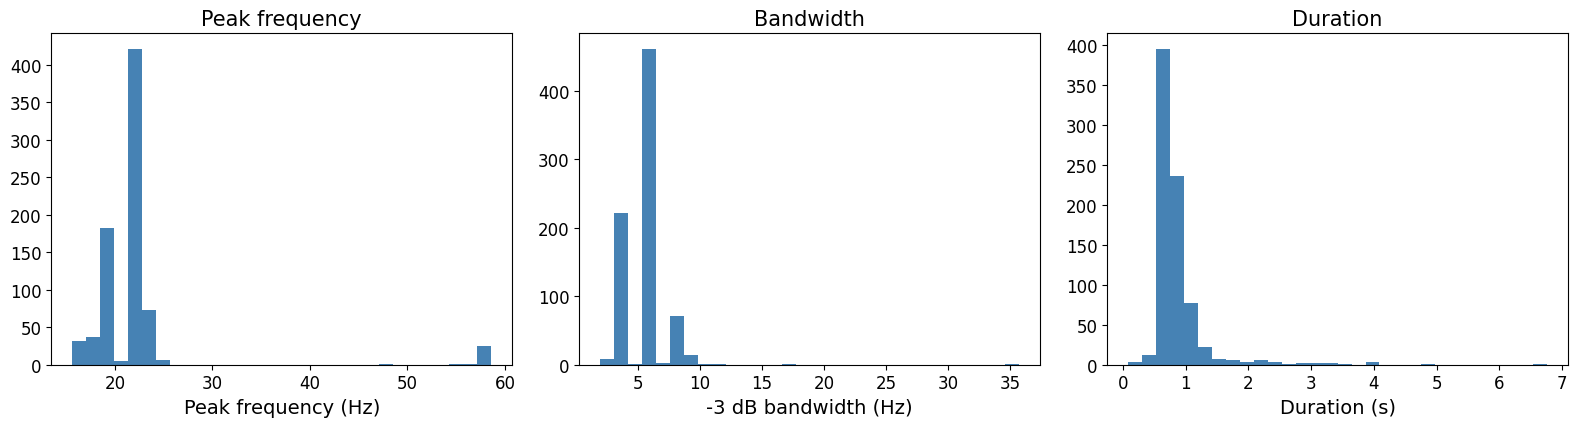

       duration_s  peak_freq_hz  center_freq_hz  bandwidth_hz  start_freq_hz  \
count  783.000000    783.000000      782.000000    783.000000     782.000000   
mean     0.854572     22.123534       20.510487      5.581692      21.693562   
std      0.479568      7.131224        3.734796      1.778172       4.363347   
min      0.082000     15.625000        7.812500      1.953125       7.812500   
25%      0.656000     19.531250       18.488104      3.906250      20.833333   
50%      0.738000     21.484375       21.484375      5.859375      23.437500   
75%      0.882000     21.484375       23.437500      5.859375      23.437500   
max      6.760000     58.593750       35.156250     35.714286      39.062500   

       end_freq_hz         snr  
count   782.000000  783.000000  
mean     19.327412    3.522151  
std       4.892367    1.770693  
min       7.812500    1.150983  
25%      16.493056    2.543987  
50%      20.312500    3.191454  
75%      23.437500    3.965727  
max      35.156

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(c20["peak_freq_hz"].dropna(), bins=30, color="steelblue")
axes[0].set_xlabel("Peak frequency (Hz)"); axes[0].set_title("Peak frequency")
axes[1].hist(c20["bandwidth_hz"].dropna(), bins=30, color="steelblue")
axes[1].set_xlabel("-3 dB bandwidth (Hz)"); axes[1].set_title("Bandwidth")
axes[2].hist(c20["duration_s"].dropna(), bins=30, color="steelblue")
axes[2].set_xlabel("Duration (s)"); axes[2].set_title("Duration")
fig.tight_layout()
fig.savefig(FIGDIR / "31_call_metrics_summary.png", dpi=130)
plt.show()

print(c20[["duration_s", "peak_freq_hz", "center_freq_hz", "bandwidth_hz",
          "start_freq_hz", "end_freq_hz", "snr"]].describe())

## 7. Export

In [11]:
calls_out = calls.merge(
    ipi_df[["file", "sel_a", "ipi_s", "same_individual"]].rename(
        columns={"sel_a": "sel", "ipi_s": "ipi_to_next_s", "same_individual": "ipi_same_individual"}),
    on=["file", "sel"], how="left")
calls_out.to_csv(OUTDIR / "call_metrics_verified_detections.csv", index=False)
seq_df.to_csv(OUTDIR / "call_type_sequences.csv", index=False)
print(f"wrote {OUTDIR/'call_metrics_verified_detections.csv'}  ({len(calls_out)} calls)")
print(f"wrote {OUTDIR/'call_type_sequences.csv'}  ({len(seq_df)} sequences)")

wrote /home/sjuber/interferometry-for-orcas/localization_results/data/call_metrics_verified_detections.csv  (785 calls)
wrote /home/sjuber/interferometry-for-orcas/localization_results/data/call_type_sequences.csv  (136 sequences)


## 8. Example spectrograms of each call type

In [12]:
def pick_example(call_type, min_calls=6):
    # prefer a clear, high-SNR example with several calls; fall back to whatever exists
    cand = seq_df[(seq_df.call_type == call_type) & (seq_df.n_calls >= min_calls)].copy()
    if cand.empty:
        cand = seq_df[seq_df.call_type == call_type].copy()
    if cand.empty:
        return None
    snr_by_file = c20.groupby("file")["snr"].mean()
    cand["mean_snr"] = cand["file"].map(snr_by_file)
    if call_type == "doublet":
        # pick the example with the starkest within-/between-pair contrast first --
        # that's what actually makes the grouping visible to the eye in the plot (see
        # Sirovic et al. Fig. 2); SNR only breaks ties among contrast-matched candidates
        cand["contrast"] = cand["ipi_clusters_s"].apply(lambda m: max(m) / min(m))
        return cand.sort_values(["contrast", "mean_snr"], ascending=False).iloc[0]
    if call_type == "triplet":
        # genuine triplets (period-3 A,A,B cycling) are rare and short in this dataset
        # -- a single A,A,B repeat only shows the pattern once, which barely reads as
        # "cyclic" by eye. Prefer the longest available run so the repeat is actually
        # visible more than once, over a shorter run that merely has higher contrast.
        cand["contrast"] = cand["ipi_clusters_s"].apply(lambda m: max(m) / min(m))
        return cand.sort_values(["n_calls", "contrast", "mean_snr"], ascending=False).iloc[0]
    return cand.sort_values("mean_snr", ascending=False).iloc[0]

example_types = ["singlet", "doublet", "triplet", "irregular"]
examples = {t: pick_example(t) for t in example_types}
for t, row in examples.items():
    if row is not None:
        print(f"{t}: {row['file']}  n_calls={row['n_calls']}  "
             f"IPI clusters(s)={[round(v, 1) for v in row['ipi_clusters_s']]}")
    else:
        print(f"{t}: no example available")

singlet: MorroPhase_base_20241106_225554_ch5700m.wav  n_calls=11  IPI clusters(s)=[12.7]
doublet: MorroPhase_base_20241107_183504_ch7500m.wav  n_calls=10  IPI clusters(s)=[1.5, 23.0]
triplet: no example available
irregular: MorroPhase_base_20241112_192324_ch7200m.wav  n_calls=11  IPI clusters(s)=[2.2, 9.6, 19.7]


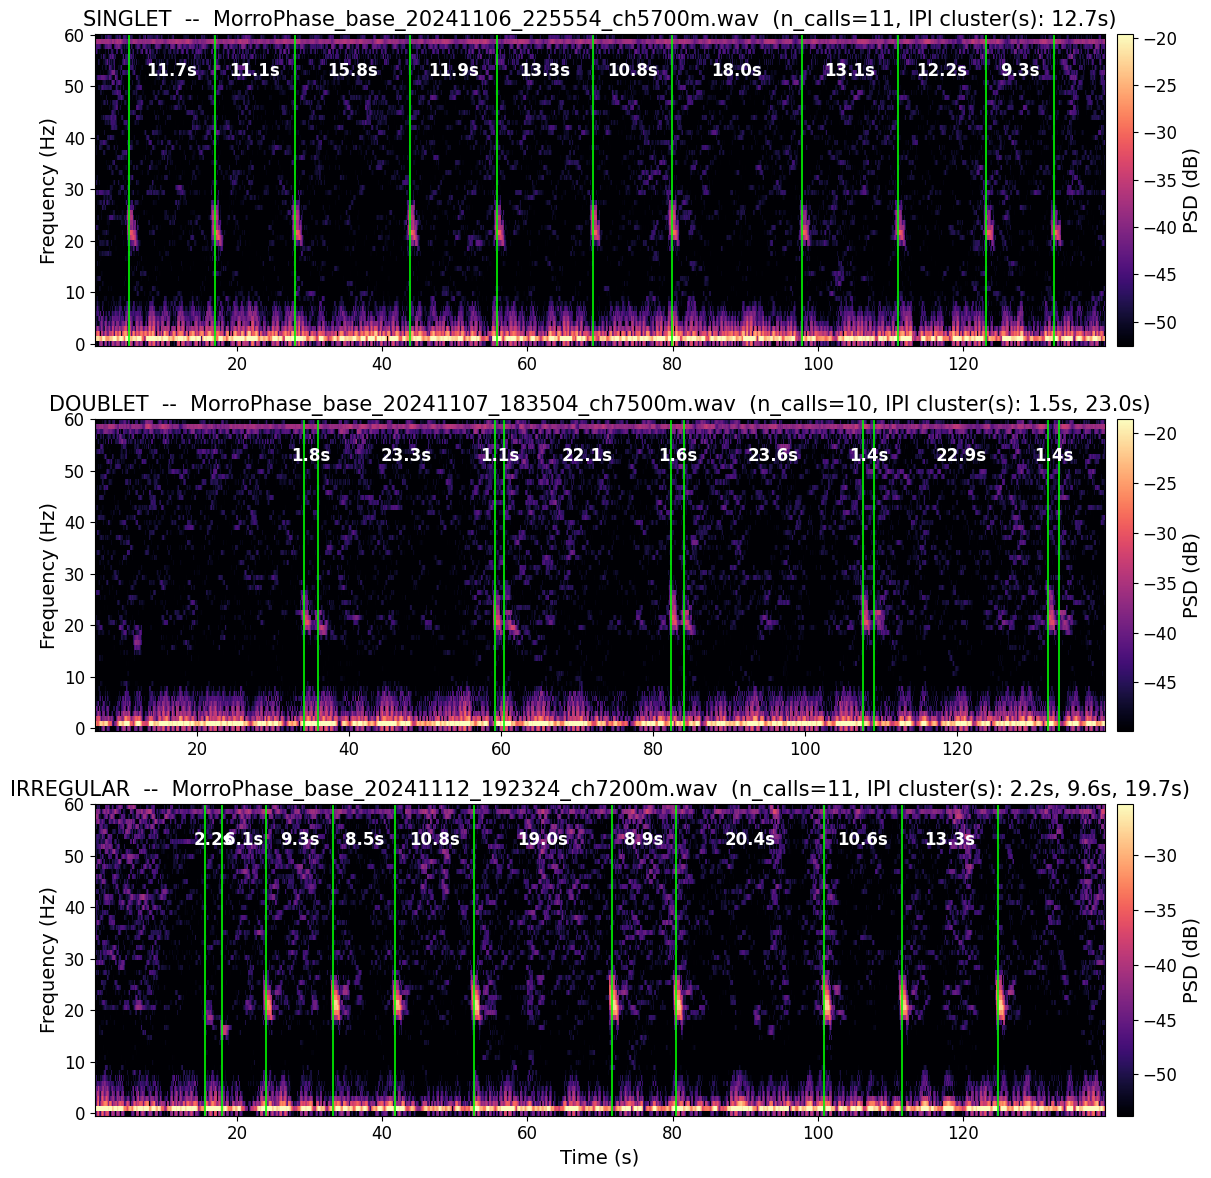

In [13]:
def render_example_ax(ax, ctype, row, pad_s=28.0):
    # Shared by section 8 (one example/type) and section 9 (several/type). Widened
    # from the original +-5/8s pad to +-15s and now also shows any confirmed 20Hz
    # call that falls in that wider window but was EXCLUDED from the classified run
    # (SNR-gate mismatch with its neighbor, or just outside the run boundary) --
    # Sam's suggestion, to check by eye whether a pattern plausibly continues just
    # past where the run was cut, rather than only ever seeing the run in isolation.
    fn = row["file"]
    trace, fs = _cache[fn] if fn in _cache else sf.read(str(WAVDIR / fn))
    in_run = c20[c20["sel"].isin(row["sels"])].sort_values("t_start_s")
    ts_run = in_run["t_start_s"].values
    t0 = max(0.0, ts_run.min() - pad_s)
    t1 = min(len(trace) / fs, ts_run.max() + pad_s)
    nearby = c20[(c20["file"] == fn) & (c20["t_start_s"] >= t0) & (c20["t_start_s"] <= t1)]
    excluded = nearby[~nearby["sel"].isin(row["sels"])].sort_values("t_start_s")

    seg = detrend(trace[int(t0 * fs): int(t1 * fs)])
    f_, ts_, Sxx = spectrogram(seg, fs=fs, nperseg=512, noverlap=int(0.9 * 512))
    Sxx_db = 10 * np.log10(Sxx + 1e-20)
    m = f_ <= 60
    im = ax.pcolormesh(ts_ + t0, f_[m], Sxx_db[m], shading="auto", cmap="magma",
                       vmin=np.percentile(Sxx_db[m], 55), vmax=np.percentile(Sxx_db[m], 99.5))
    for t in ts_run:
        ax.axvline(t, color="lime", lw=1.3, alpha=0.9)
    for a, b in zip(ts_run[:-1], ts_run[1:]):
        ax.annotate(f"{b - a:.1f}s", xy=((a + b) / 2, 52), ha="center", color="white",
                   fontsize=12, weight="bold")
    for t in excluded["t_start_s"].values:
        ax.axvline(t, color="orange", lw=1.2, alpha=0.85, ls="--")
    ax.set_ylabel("Frequency (Hz)")
    ipi_str = ", ".join(f"{v:.1f}s" for v in row["ipi_clusters_s"])
    extra = f"  (+{len(excluded)} excluded call(s), orange dashed)" if len(excluded) else ""
    ax.set_title(f"{ctype.upper()}  --  {fn}  (n_calls={row['n_calls']}, IPI cluster(s): {ipi_str}){extra}")
    return im


available_types = [t for t in example_types if examples[t] is not None]
fig, axes = plt.subplots(len(available_types), 1, figsize=(13, 4 * len(available_types)), squeeze=False)
axes = axes[:, 0]
for ax, ctype in zip(axes, available_types):
    im = render_example_ax(ax, ctype, examples[ctype])
    fig.colorbar(im, ax=ax, label="PSD (dB)", pad=0.01)
axes[-1].set_xlabel("Time (s)")
fig.tight_layout()
fig.savefig(FIGDIR / "32_call_type_examples.png", dpi=130)
plt.show()

## 9. More examples per call type

In [14]:
def pick_examples(call_type, k=4, min_calls=6):
    # same ranking as pick_example (section 8), but returns the top k instead of 1
    cand = seq_df[(seq_df.call_type == call_type) & (seq_df.n_calls >= min_calls)].copy()
    if cand.empty:
        cand = seq_df[seq_df.call_type == call_type].copy()
    if cand.empty:
        return []
    snr_by_file = c20.groupby("file")["snr"].mean()
    cand["mean_snr"] = cand["file"].map(snr_by_file)
    if call_type in ("doublet", "triplet"):
        cand["contrast"] = cand["ipi_clusters_s"].apply(lambda m: max(m) / min(m))
    if call_type == "doublet":
        cand = cand.sort_values(["contrast", "mean_snr"], ascending=False)
    elif call_type == "triplet":
        cand = cand.sort_values(["n_calls", "contrast", "mean_snr"], ascending=False)
    else:
        cand = cand.sort_values("mean_snr", ascending=False)
    return [r for _, r in cand.head(k).iterrows()]


def plot_examples_panel(ctype, rows, fig_num):
    if not rows:
        print(f"{ctype}: no examples available")
        return
    fig, axes = plt.subplots(len(rows), 1, figsize=(13, 4 * len(rows)), squeeze=False)
    axes = axes[:, 0]
    for ax, row in zip(axes, rows):
        im = render_example_ax(ax, ctype, row)
        fig.colorbar(im, ax=ax, label="PSD (dB)", pad=0.01)
    axes[-1].set_xlabel("Time (s)")
    fig.tight_layout()
    fig.savefig(FIGDIR / f"{fig_num}_call_type_examples_{ctype}.png", dpi=130)
    plt.show()


more_examples = {t: pick_examples(t, k=4) for t in example_types}
for t, rows in more_examples.items():
    print(f"{t}: {len(rows)} example(s), files: {[r['file'] for r in rows]}")

singlet: 4 example(s), files: ['MorroPhase_base_20241106_225554_ch5700m.wav', 'MorroPhase_base_20241107_184144_ch7200m.wav', 'MorroPhase_base_20241106_212234_ch8100m.wav', 'MorroPhase_base_20241106_202414_ch7200m.wav']
doublet: 4 example(s), files: ['MorroPhase_base_20241107_183504_ch7500m.wav', 'MorroPhase_base_20241108_195324_ch8400m.wav', 'MorroPhase_base_20241108_202504_ch8100m.wav', 'MorroPhase_base_20241107_173504_ch8100m.wav']
triplet: 0 example(s), files: []
irregular: 4 example(s), files: ['MorroPhase_base_20241112_192324_ch7200m.wav', 'MorroPhase_base_20241106_035734_ch8400m.wav', 'MorroPhase_base_20241106_232414_ch5400m.wav', 'MorroPhase_base_20241112_150324_ch7200m.wav']


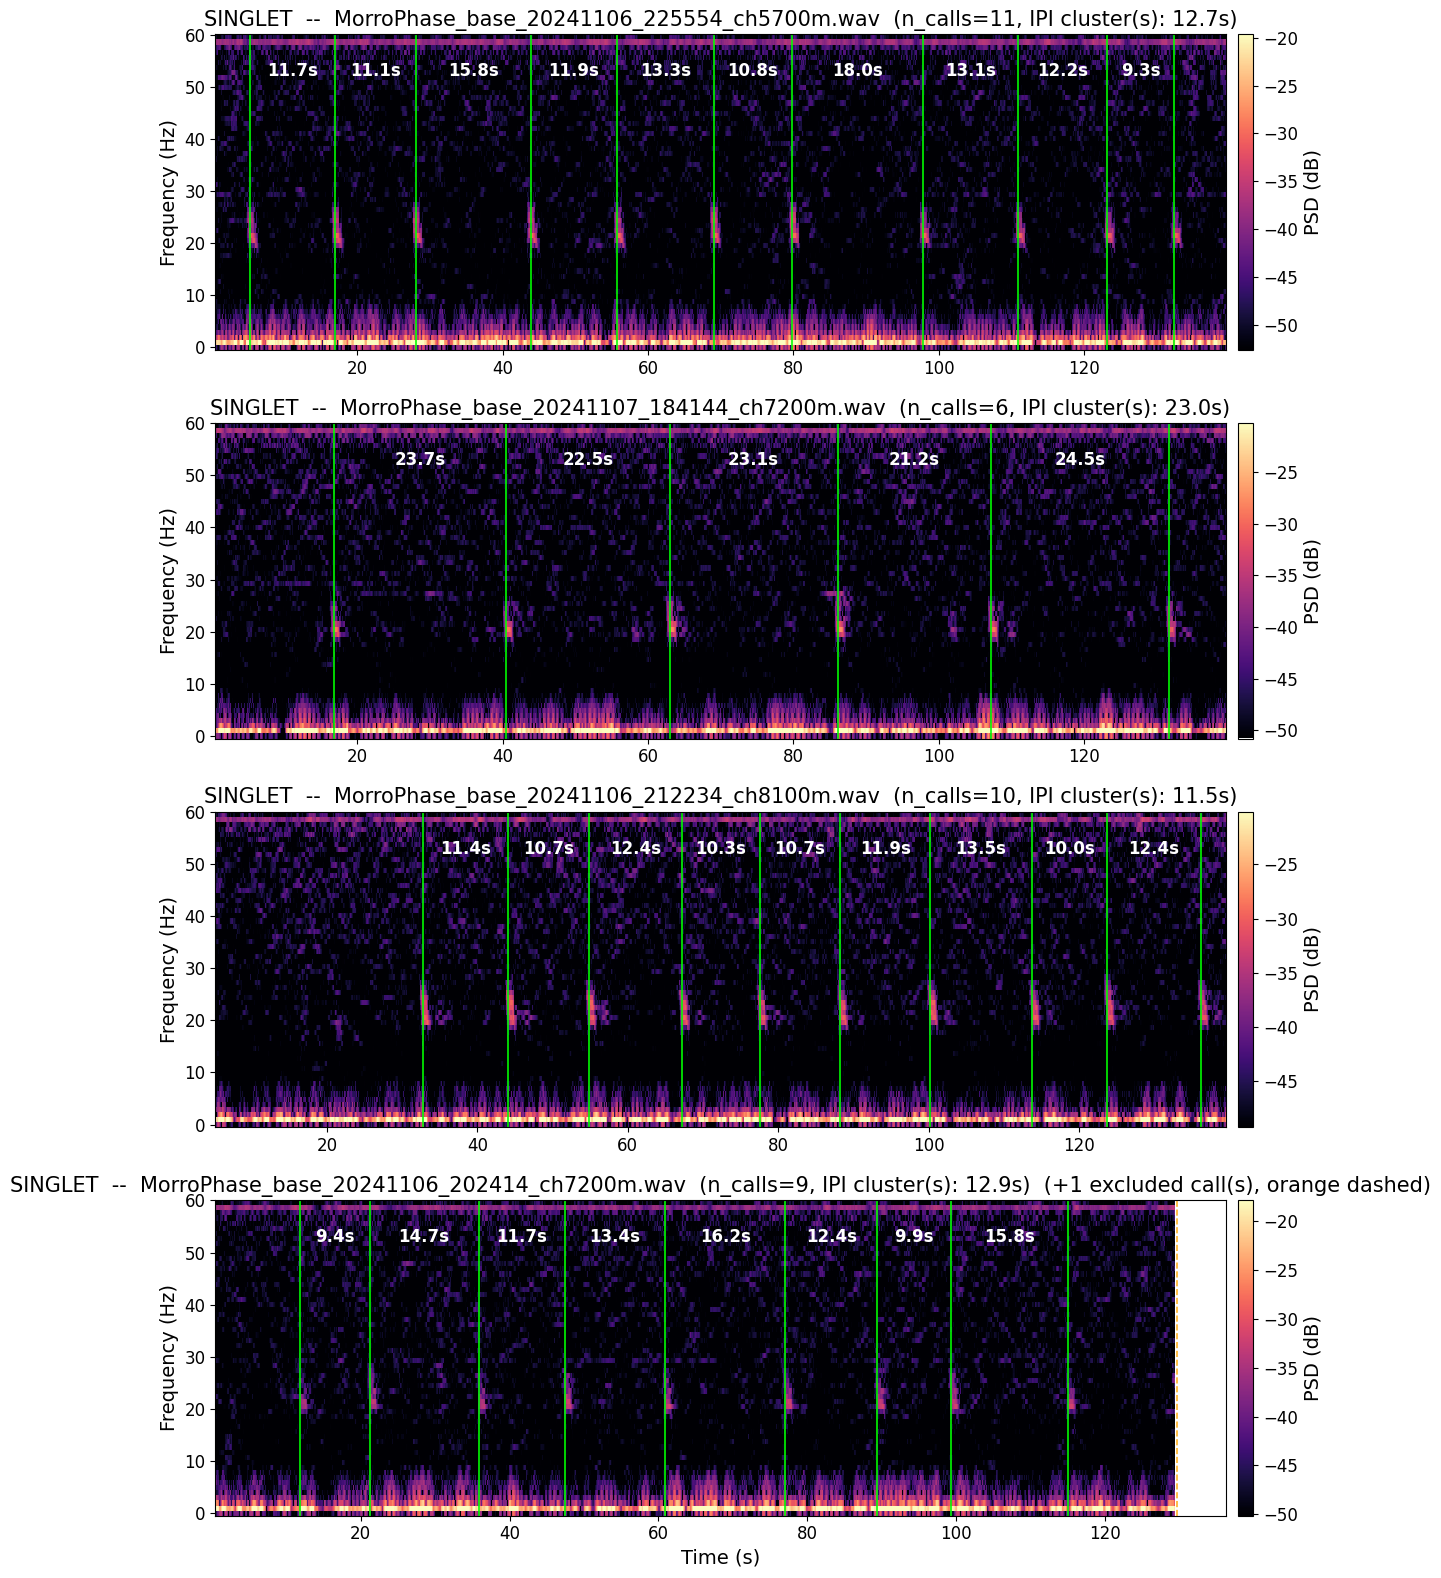

In [15]:
plot_examples_panel("singlet", more_examples["singlet"], 34)

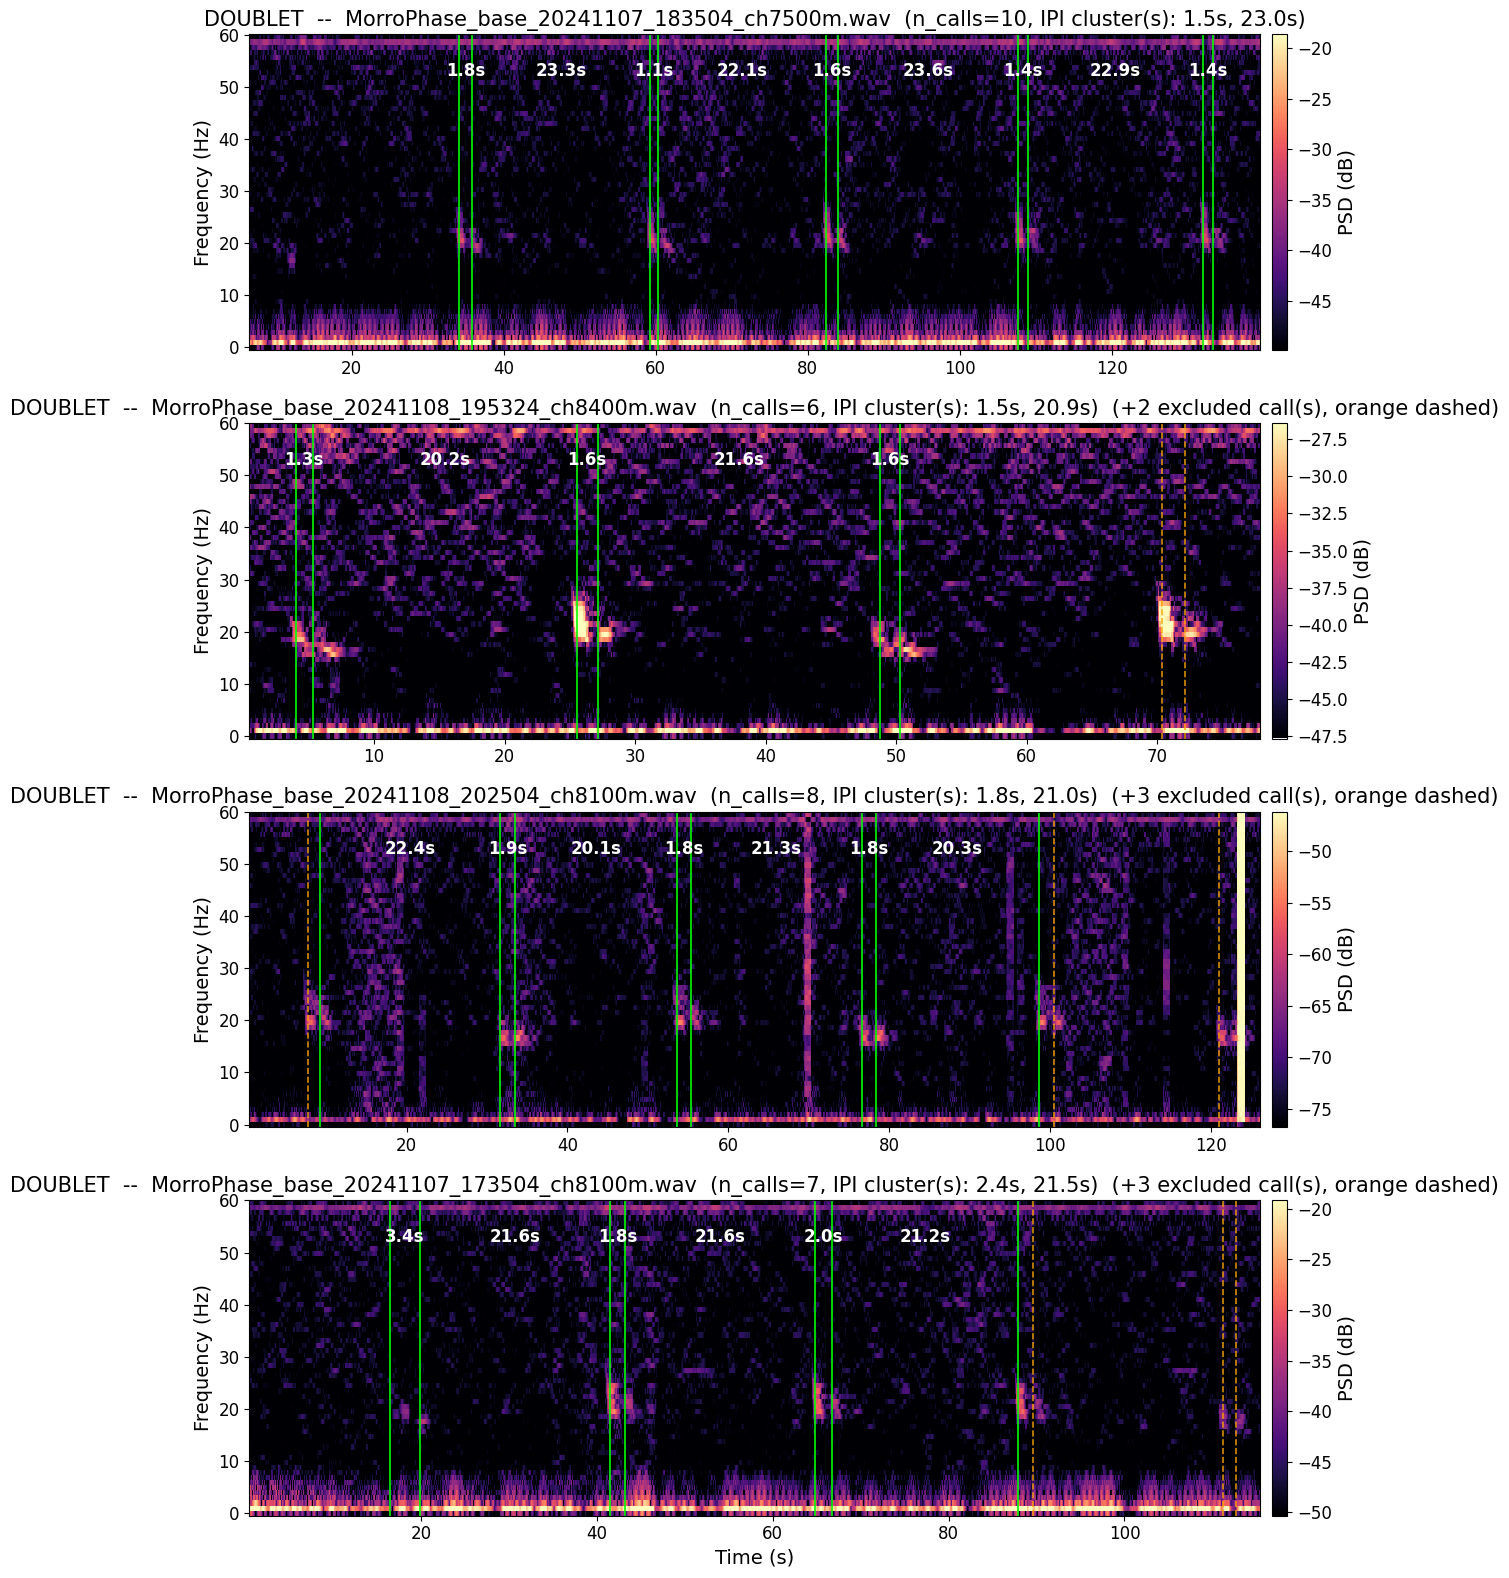

In [16]:
plot_examples_panel("doublet", more_examples["doublet"], 35)

In [17]:
plot_examples_panel("triplet", more_examples["triplet"], 36)

triplet: no examples available


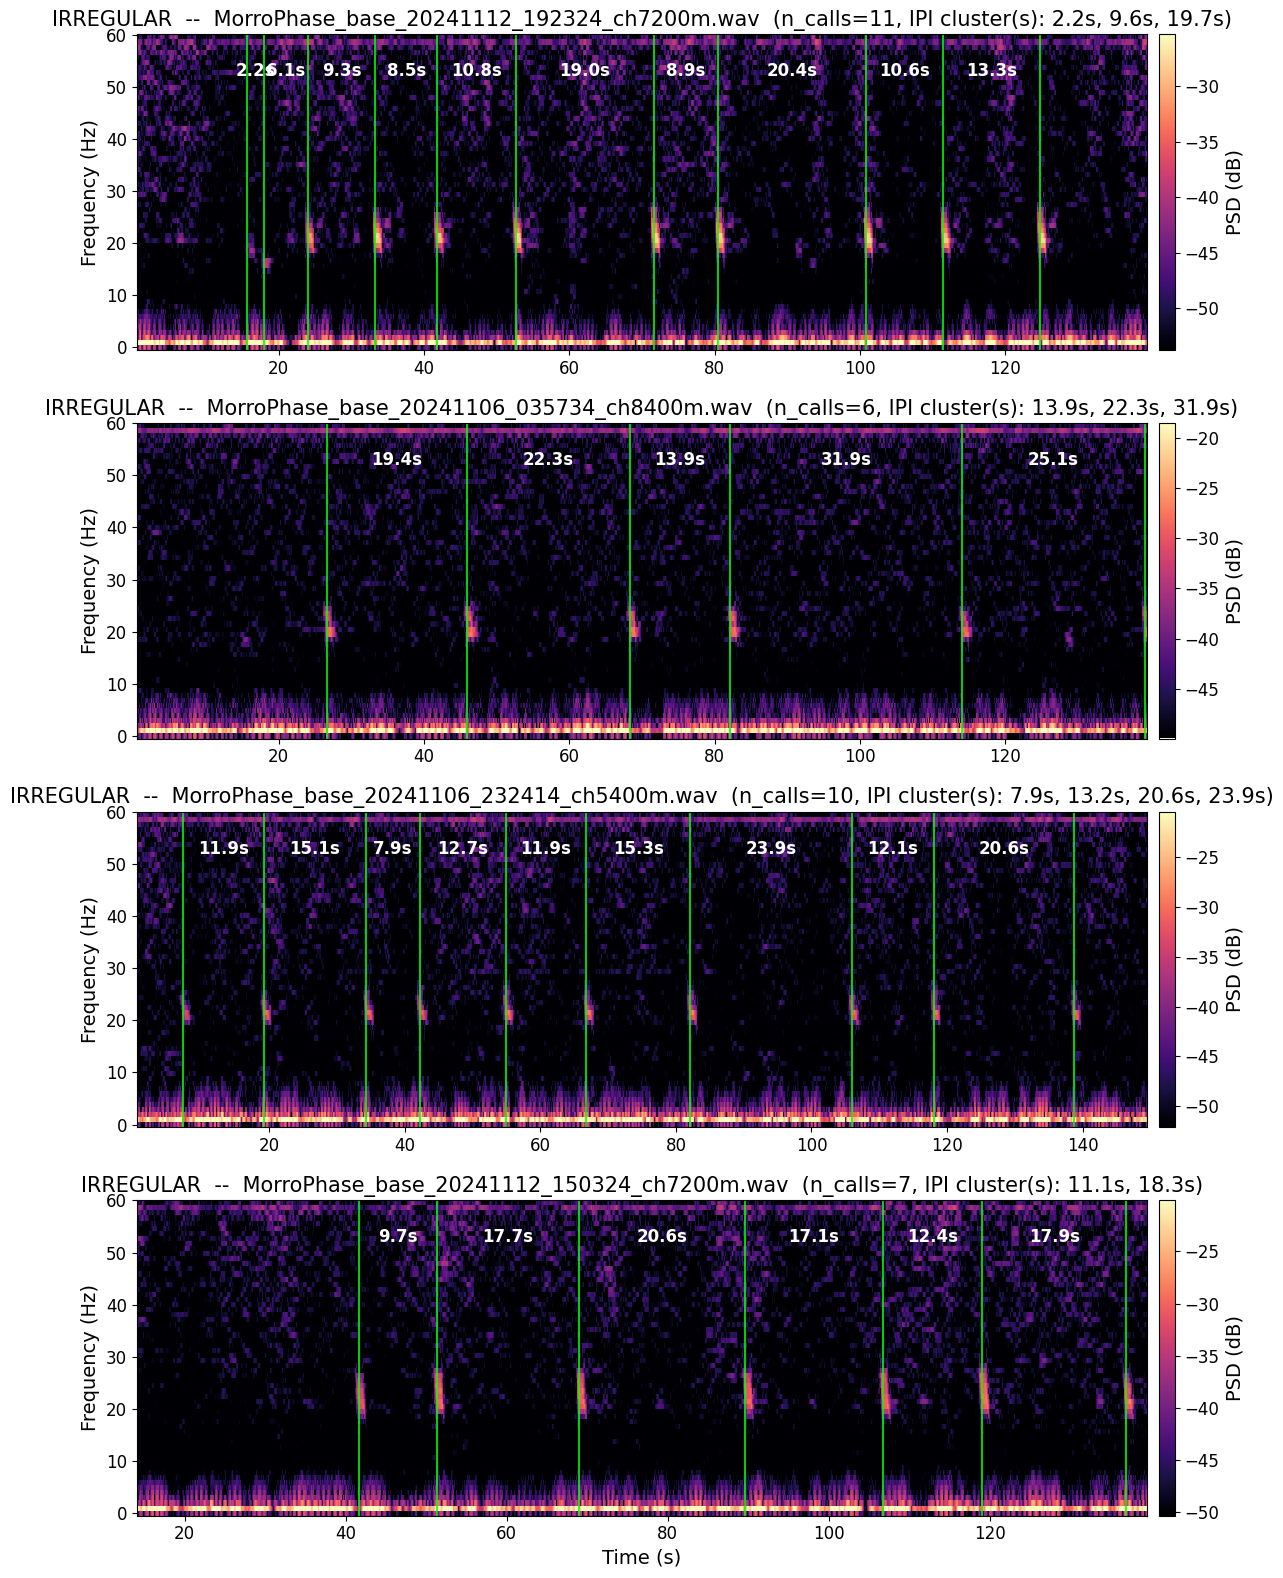

In [18]:
plot_examples_panel("irregular", more_examples["irregular"], 37)